# Large Language Models for Sensor Data Analysis

## HBTA Structural Health Monitoring — Autoencoder Implementation

### Project Objective
This notebook investigates the use of a Conv1D Autoencoder for analysing vibration sensor data from the HBTA dataset. The objective is to train the model using healthy sensor measurements and evaluate whether reconstruction errors can distinguish healthy and damaged structural conditions.

### Workflow
1. Load and explore the HBTA dataset.
2. Preprocess and standardise sensor measurements.
3. Divide the data into fixed-length windows.
4. Train an existing Conv1D Autoencoder architecture.
5. Evaluate the model using reconstruction error and ROC-AUC.
6. Compare experimental results and discuss limitations.

## 1. HBTA Dataset Loading and Exploration

This section loads the HBTA structural health monitoring dataset stored in HDF5 format and examines its measurement groups and sensor channels.

In [19]:
import h5py
from pathlib import Path

# Location of the HBTA dataset
file_path = Path.home() / "Downloads" / "data_100Hz.h5"

# Check that the dataset exists
if not file_path.exists():
    raise FileNotFoundError(f"Dataset not found: {file_path}")

# Open the dataset
h5 = h5py.File(file_path, "r")

print("File opened successfully")
print("Top-level groups:")
print(list(h5.keys()))

File opened successfully
Top-level groups:
['MVS_P1_DS1_SM_Y_01', 'MVS_P1_DS1_SM_Z_01', 'MVS_P1_DS2_SM_Y_01', 'MVS_P1_DS2_SM_Z_01', 'MVS_P1_DS3_SM_Y_01', 'MVS_P1_DS3_SM_Z_01', 'MVS_P1_DS4_SM_Y_01', 'MVS_P1_DS4_SM_Z_01', 'MVS_P1_DS5_SM_Y_01', 'MVS_P1_DS5_SM_Z_01', 'MVS_P1_DS6_SM_Y_01', 'MVS_P1_DS6_SM_Z_01', 'MVS_P1_DS7_SM_Y_01', 'MVS_P1_DS7_SM_Z_01', 'MVS_P1_DS8_SM_Y_01', 'MVS_P1_DS8_SM_Z_01', 'MVS_P1_UDS_SM_Y_01', 'MVS_P1_UDS_SM_Y_02', 'MVS_P1_UDS_SM_Z_01', 'MVS_P1_UDS_SM_Z_02', 'MVS_P2_DS1_NM_Z_01', 'MVS_P2_DS1_SM_Y_01', 'MVS_P2_DS1_SM_Z_01', 'MVS_P2_DS2_NM_Z_01', 'MVS_P2_DS2_SM_Y_01', 'MVS_P2_DS2_SM_Z_01', 'MVS_P2_DS3_NM_Z_01', 'MVS_P2_DS3_SM_Y_01', 'MVS_P2_DS3_SM_Z_01', 'MVS_P2_DS4_NM_Z_01', 'MVS_P2_DS4_SM_Y_01', 'MVS_P2_DS4_SM_Z_01', 'MVS_P2_DS5_NM_Z_01', 'MVS_P2_DS5_SM_Y_01', 'MVS_P2_DS5_SM_Z_01', 'MVS_P2_DS6_NM_Z_01', 'MVS_P2_DS6_SM_Y_01', 'MVS_P2_DS6_SM_Z_01', 'MVS_P2_DS7_NM_Z_01', 'MVS_P2_DS7_SM_Y_01', 'MVS_P2_DS7_SM_Z_01', 'MVS_P2_DS8_NM_Z_01', 'MVS_P2_DS8_SM_Y_01', 'MVS_P2_DS

In [20]:
def show_structure(name, obj):
    if isinstance(obj, h5py.Dataset):
        print(name, obj.shape, obj.dtype)
    else:
        print(name)

h5.visititems(show_structure)

MVS_P1_DS1_SM_Y_01
MVS_P1_DS1_SM_Y_01/acceleration
MVS_P1_DS1_SM_Y_01/acceleration/AG01
MVS_P1_DS1_SM_Y_01/acceleration/AG01/y (62221,) float64
MVS_P1_DS1_SM_Y_01/acceleration/AG01/z (62221,) float64
MVS_P1_DS1_SM_Y_01/acceleration/AG02
MVS_P1_DS1_SM_Y_01/acceleration/AG02/y (62221,) float64
MVS_P1_DS1_SM_Y_01/acceleration/AG02/z (62221,) float64
MVS_P1_DS1_SM_Y_01/acceleration/AG03
MVS_P1_DS1_SM_Y_01/acceleration/AG03/y (62221,) float64
MVS_P1_DS1_SM_Y_01/acceleration/AG03/z (62221,) float64
MVS_P1_DS1_SM_Y_01/acceleration/AG04
MVS_P1_DS1_SM_Y_01/acceleration/AG04/y (62221,) float64
MVS_P1_DS1_SM_Y_01/acceleration/AG04/z (62221,) float64
MVS_P1_DS1_SM_Y_01/acceleration/AG05
MVS_P1_DS1_SM_Y_01/acceleration/AG05/y (62221,) float64
MVS_P1_DS1_SM_Y_01/acceleration/AG05/z (62221,) float64
MVS_P1_DS1_SM_Y_01/acceleration/AG06
MVS_P1_DS1_SM_Y_01/acceleration/AG06/y (62221,) float64
MVS_P1_DS1_SM_Y_01/acceleration/AG06/z (62221,) float64
MVS_P1_DS1_SM_Y_01/acceleration/AG07
MVS_P1_DS1_SM_Y_01

In [21]:
signal = h5["MVS_P1_DS1_SM_Y_01/acceleration/AG01/y"][:]

print("Number of samples:", len(signal))
print("First 10 values:")
print(signal[:10])

print("Minimum:", signal.min())
print("Maximum:", signal.max())
print("Mean:", signal.mean())
print("Standard deviation:", signal.std())

Number of samples: 62221
First 10 values:
[ 0.00093149  0.0011044   0.00119229  0.00089972  0.00068361  0.00028901
 -0.0007714  -0.00095839 -0.00094081 -0.00098731]
Minimum: -0.2177277438279785
Maximum: 0.21834512824978453
Mean: 3.3825432658264624e-09
Standard deviation: 0.0330667496418243


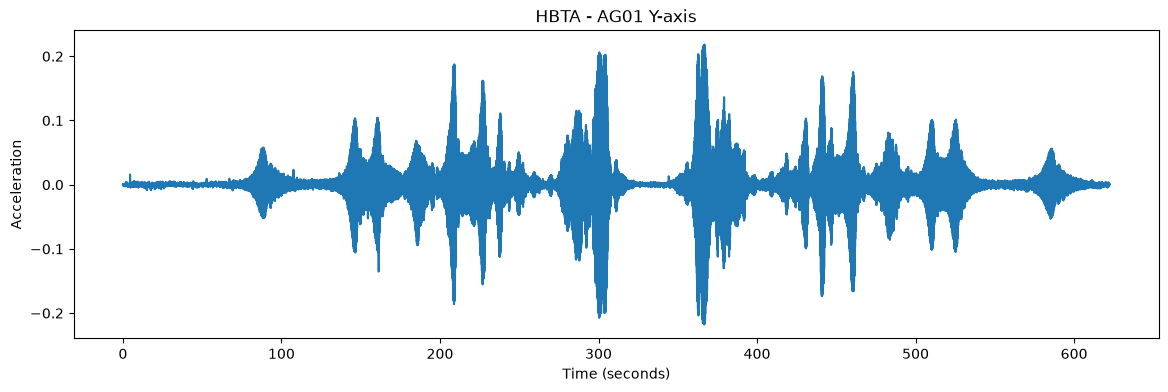

In [22]:
import matplotlib.pyplot as plt
import numpy as np

fs = 100

time = np.arange(len(signal)) / fs

plt.figure(figsize=(14, 4))
plt.plot(time, signal)
plt.xlabel("Time (seconds)")
plt.ylabel("Acceleration")
plt.title("HBTA - AG01 Y-axis")
plt.show()

In [23]:
print("NaN values:", np.isnan(signal).sum())
print("Infinite values:", np.isinf(signal).sum())


NaN values: 0
Infinite values: 0


In [24]:
groups = list(h5.keys())

print("Number of measurement groups:", len(groups))

for group in groups:
    print(group)

Number of measurement groups: 50
MVS_P1_DS1_SM_Y_01
MVS_P1_DS1_SM_Z_01
MVS_P1_DS2_SM_Y_01
MVS_P1_DS2_SM_Z_01
MVS_P1_DS3_SM_Y_01
MVS_P1_DS3_SM_Z_01
MVS_P1_DS4_SM_Y_01
MVS_P1_DS4_SM_Z_01
MVS_P1_DS5_SM_Y_01
MVS_P1_DS5_SM_Z_01
MVS_P1_DS6_SM_Y_01
MVS_P1_DS6_SM_Z_01
MVS_P1_DS7_SM_Y_01
MVS_P1_DS7_SM_Z_01
MVS_P1_DS8_SM_Y_01
MVS_P1_DS8_SM_Z_01
MVS_P1_UDS_SM_Y_01
MVS_P1_UDS_SM_Y_02
MVS_P1_UDS_SM_Z_01
MVS_P1_UDS_SM_Z_02
MVS_P2_DS1_NM_Z_01
MVS_P2_DS1_SM_Y_01
MVS_P2_DS1_SM_Z_01
MVS_P2_DS2_NM_Z_01
MVS_P2_DS2_SM_Y_01
MVS_P2_DS2_SM_Z_01
MVS_P2_DS3_NM_Z_01
MVS_P2_DS3_SM_Y_01
MVS_P2_DS3_SM_Z_01
MVS_P2_DS4_NM_Z_01
MVS_P2_DS4_SM_Y_01
MVS_P2_DS4_SM_Z_01
MVS_P2_DS5_NM_Z_01
MVS_P2_DS5_SM_Y_01
MVS_P2_DS5_SM_Z_01
MVS_P2_DS6_NM_Z_01
MVS_P2_DS6_SM_Y_01
MVS_P2_DS6_SM_Z_01
MVS_P2_DS7_NM_Z_01
MVS_P2_DS7_SM_Y_01
MVS_P2_DS7_SM_Z_01
MVS_P2_DS8_NM_Z_01
MVS_P2_DS8_SM_Y_01
MVS_P2_DS8_SM_Z_01
MVS_P2_UDS_NM_Z_01
MVS_P2_UDS_NM_Z_02
MVS_P2_UDS_SM_Y_01
MVS_P2_UDS_SM_Y_02
MVS_P2_UDS_SM_Z_01
MVS_P2_UDS_SM_Z_02


In [25]:
groups = list(h5.keys())

print("Number of measurement groups:", len(groups))

for group in groups:
    print(group)

Number of measurement groups: 50
MVS_P1_DS1_SM_Y_01
MVS_P1_DS1_SM_Z_01
MVS_P1_DS2_SM_Y_01
MVS_P1_DS2_SM_Z_01
MVS_P1_DS3_SM_Y_01
MVS_P1_DS3_SM_Z_01
MVS_P1_DS4_SM_Y_01
MVS_P1_DS4_SM_Z_01
MVS_P1_DS5_SM_Y_01
MVS_P1_DS5_SM_Z_01
MVS_P1_DS6_SM_Y_01
MVS_P1_DS6_SM_Z_01
MVS_P1_DS7_SM_Y_01
MVS_P1_DS7_SM_Z_01
MVS_P1_DS8_SM_Y_01
MVS_P1_DS8_SM_Z_01
MVS_P1_UDS_SM_Y_01
MVS_P1_UDS_SM_Y_02
MVS_P1_UDS_SM_Z_01
MVS_P1_UDS_SM_Z_02
MVS_P2_DS1_NM_Z_01
MVS_P2_DS1_SM_Y_01
MVS_P2_DS1_SM_Z_01
MVS_P2_DS2_NM_Z_01
MVS_P2_DS2_SM_Y_01
MVS_P2_DS2_SM_Z_01
MVS_P2_DS3_NM_Z_01
MVS_P2_DS3_SM_Y_01
MVS_P2_DS3_SM_Z_01
MVS_P2_DS4_NM_Z_01
MVS_P2_DS4_SM_Y_01
MVS_P2_DS4_SM_Z_01
MVS_P2_DS5_NM_Z_01
MVS_P2_DS5_SM_Y_01
MVS_P2_DS5_SM_Z_01
MVS_P2_DS6_NM_Z_01
MVS_P2_DS6_SM_Y_01
MVS_P2_DS6_SM_Z_01
MVS_P2_DS7_NM_Z_01
MVS_P2_DS7_SM_Y_01
MVS_P2_DS7_SM_Z_01
MVS_P2_DS8_NM_Z_01
MVS_P2_DS8_SM_Y_01
MVS_P2_DS8_SM_Z_01
MVS_P2_UDS_NM_Z_01
MVS_P2_UDS_NM_Z_02
MVS_P2_UDS_SM_Y_01
MVS_P2_UDS_SM_Y_02
MVS_P2_UDS_SM_Z_01
MVS_P2_UDS_SM_Z_02


In [26]:
selected_groups = [
    name for name in h5.keys()
    if name.startswith("MVS_P1_")
    and "_SM_Y_" in name
]

print("Selected groups:", len(selected_groups))

for group in selected_groups:
    sensors = list(h5[group]["acceleration"].keys())
    print(group, ":", sensors)

Selected groups: 10
MVS_P1_DS1_SM_Y_01 : ['AG01', 'AG02', 'AG03', 'AG04', 'AG05', 'AG06', 'AG07', 'AG08', 'AG09', 'AG10', 'AG11', 'AG12', 'AG13', 'AG14', 'AG15', 'AG16', 'AG17', 'AG18', 'AL01', 'AL02', 'AL03', 'AL04', 'AL05', 'AL06', 'AL07', 'AL08', 'AL09', 'AL10', 'AL11', 'AL12', 'AL13', 'AL14', 'AL15', 'AL16', 'AL17', 'AL18', 'AL19', 'AL20', 'AL21', 'AL22', 'AL23', 'AL24', 'AL25', 'AL26', 'AL27', 'AL28', 'AL29', 'AL30', 'AL31', 'AL32', 'AL33', 'AL34', 'AL35', 'AL36', 'AL37', 'AL38', 'AL39', 'AL40', 'AS']
MVS_P1_DS2_SM_Y_01 : ['AG01', 'AG02', 'AG03', 'AG04', 'AG05', 'AG06', 'AG07', 'AG08', 'AG09', 'AG10', 'AG11', 'AG12', 'AG13', 'AG14', 'AG15', 'AG16', 'AG17', 'AG18', 'AL01', 'AL02', 'AL03', 'AL04', 'AL05', 'AL06', 'AL07', 'AL08', 'AL09', 'AL10', 'AL11', 'AL12', 'AL13', 'AL14', 'AL15', 'AL16', 'AL17', 'AL18', 'AL19', 'AL20', 'AL21', 'AL22', 'AL23', 'AL24', 'AL25', 'AL26', 'AL27', 'AL28', 'AL29', 'AL30', 'AL31', 'AL32', 'AL33', 'AL34', 'AL35', 'AL36', 'AL37', 'AL38', 'AL39', 'AL40', 'A

In [27]:
ag_sensors = [f"AG{i:02d}" for i in range(1, 19)]

print(ag_sensors)


['AG01', 'AG02', 'AG03', 'AG04', 'AG05', 'AG06', 'AG07', 'AG08', 'AG09', 'AG10', 'AG11', 'AG12', 'AG13', 'AG14', 'AG15', 'AG16', 'AG17', 'AG18']


In [28]:
group = "MVS_P1_UDS_SM_Y_01"

for sensor in ag_sensors:
    axes = list(h5[group]["acceleration"][sensor].keys())
    print(sensor, axes)

AG01 ['y', 'z']
AG02 ['y', 'z']
AG03 ['y', 'z']
AG04 ['y', 'z']
AG05 ['y', 'z']
AG06 ['y', 'z']
AG07 ['y', 'z']
AG08 ['y', 'z']
AG09 ['z']
AG10 ['y', 'z']
AG11 ['y', 'z']
AG12 ['y', 'z']
AG13 ['y', 'z']
AG14 ['y', 'z']
AG15 ['y', 'z']
AG16 ['y', 'z']
AG17 ['y', 'z']
AG18 ['y', 'z']


In [30]:
healthy_group = "MVS_P1_UDS_SM_Y_01"

print("Healthy group:", healthy_group)
print("Available groups:", list(h5.keys()))
print("Group exists:", healthy_group in h5)

Healthy group: MVS_P1_UDS_SM_Y_01
Available groups: ['MVS_P1_DS1_SM_Y_01', 'MVS_P1_DS1_SM_Z_01', 'MVS_P1_DS2_SM_Y_01', 'MVS_P1_DS2_SM_Z_01', 'MVS_P1_DS3_SM_Y_01', 'MVS_P1_DS3_SM_Z_01', 'MVS_P1_DS4_SM_Y_01', 'MVS_P1_DS4_SM_Z_01', 'MVS_P1_DS5_SM_Y_01', 'MVS_P1_DS5_SM_Z_01', 'MVS_P1_DS6_SM_Y_01', 'MVS_P1_DS6_SM_Z_01', 'MVS_P1_DS7_SM_Y_01', 'MVS_P1_DS7_SM_Z_01', 'MVS_P1_DS8_SM_Y_01', 'MVS_P1_DS8_SM_Z_01', 'MVS_P1_UDS_SM_Y_01', 'MVS_P1_UDS_SM_Y_02', 'MVS_P1_UDS_SM_Z_01', 'MVS_P1_UDS_SM_Z_02', 'MVS_P2_DS1_NM_Z_01', 'MVS_P2_DS1_SM_Y_01', 'MVS_P2_DS1_SM_Z_01', 'MVS_P2_DS2_NM_Z_01', 'MVS_P2_DS2_SM_Y_01', 'MVS_P2_DS2_SM_Z_01', 'MVS_P2_DS3_NM_Z_01', 'MVS_P2_DS3_SM_Y_01', 'MVS_P2_DS3_SM_Z_01', 'MVS_P2_DS4_NM_Z_01', 'MVS_P2_DS4_SM_Y_01', 'MVS_P2_DS4_SM_Z_01', 'MVS_P2_DS5_NM_Z_01', 'MVS_P2_DS5_SM_Y_01', 'MVS_P2_DS5_SM_Z_01', 'MVS_P2_DS6_NM_Z_01', 'MVS_P2_DS6_SM_Y_01', 'MVS_P2_DS6_SM_Z_01', 'MVS_P2_DS7_NM_Z_01', 'MVS_P2_DS7_SM_Y_01', 'MVS_P2_DS7_SM_Z_01', 'MVS_P2_DS8_NM_Z_01', 'MVS_P2_DS8_SM_Y_01', '

In [31]:
print("Healthy group:", healthy_group)
print("Available groups:", list(h5.keys()))

if healthy_group in h5:
    print("Inside healthy group:", list(h5[healthy_group].keys()))

    if "acceleration" in h5[healthy_group]:
        print("Available sensors:",
              list(h5[healthy_group]["acceleration"].keys()))

Healthy group: MVS_P1_UDS_SM_Y_01
Available groups: ['MVS_P1_DS1_SM_Y_01', 'MVS_P1_DS1_SM_Z_01', 'MVS_P1_DS2_SM_Y_01', 'MVS_P1_DS2_SM_Z_01', 'MVS_P1_DS3_SM_Y_01', 'MVS_P1_DS3_SM_Z_01', 'MVS_P1_DS4_SM_Y_01', 'MVS_P1_DS4_SM_Z_01', 'MVS_P1_DS5_SM_Y_01', 'MVS_P1_DS5_SM_Z_01', 'MVS_P1_DS6_SM_Y_01', 'MVS_P1_DS6_SM_Z_01', 'MVS_P1_DS7_SM_Y_01', 'MVS_P1_DS7_SM_Z_01', 'MVS_P1_DS8_SM_Y_01', 'MVS_P1_DS8_SM_Z_01', 'MVS_P1_UDS_SM_Y_01', 'MVS_P1_UDS_SM_Y_02', 'MVS_P1_UDS_SM_Z_01', 'MVS_P1_UDS_SM_Z_02', 'MVS_P2_DS1_NM_Z_01', 'MVS_P2_DS1_SM_Y_01', 'MVS_P2_DS1_SM_Z_01', 'MVS_P2_DS2_NM_Z_01', 'MVS_P2_DS2_SM_Y_01', 'MVS_P2_DS2_SM_Z_01', 'MVS_P2_DS3_NM_Z_01', 'MVS_P2_DS3_SM_Y_01', 'MVS_P2_DS3_SM_Z_01', 'MVS_P2_DS4_NM_Z_01', 'MVS_P2_DS4_SM_Y_01', 'MVS_P2_DS4_SM_Z_01', 'MVS_P2_DS5_NM_Z_01', 'MVS_P2_DS5_SM_Y_01', 'MVS_P2_DS5_SM_Z_01', 'MVS_P2_DS6_NM_Z_01', 'MVS_P2_DS6_SM_Y_01', 'MVS_P2_DS6_SM_Z_01', 'MVS_P2_DS7_NM_Z_01', 'MVS_P2_DS7_SM_Y_01', 'MVS_P2_DS7_SM_Z_01', 'MVS_P2_DS8_NM_Z_01', 'MVS_P2_DS8_SM_Y_01', '

In [32]:
import numpy as np

healthy_group = "MVS_P1_UDS_SM_Y_01"

y_sensors = []

for sensor in ag_sensors:
    if "y" in h5[healthy_group]["acceleration"][sensor].keys():
        y_sensors.append(sensor)

healthy_channels = []

for sensor in y_sensors:
    signal = h5[healthy_group]["acceleration"][sensor]["y"][:]
    healthy_channels.append(signal)

min_length = min(len(signal) for signal in healthy_channels)

healthy_data = np.column_stack([
    signal[:min_length] for signal in healthy_channels
])

print("Y-axis sensors:", y_sensors)
print("Healthy data shape:", healthy_data.shape)

Y-axis sensors: ['AG01', 'AG02', 'AG03', 'AG04', 'AG05', 'AG06', 'AG07', 'AG08', 'AG10', 'AG11', 'AG12', 'AG13', 'AG14', 'AG15', 'AG16', 'AG17', 'AG18']
Healthy data shape: (62147, 17)


In [33]:
y_sensors = []

for sensor in ag_sensors:
    axes = list(h5[healthy_group]["acceleration"][sensor].keys())

    if "y" in axes:
        y_sensors.append(sensor)

print("Y-axis sensors:", y_sensors)
print("Number of Y-axis sensors:", len(y_sensors))

Y-axis sensors: ['AG01', 'AG02', 'AG03', 'AG04', 'AG05', 'AG06', 'AG07', 'AG08', 'AG10', 'AG11', 'AG12', 'AG13', 'AG14', 'AG15', 'AG16', 'AG17', 'AG18']
Number of Y-axis sensors: 17


In [34]:
healthy_channels = []

for sensor in y_sensors:
    signal = h5[healthy_group]["acceleration"][sensor]["y"][:]
    healthy_channels.append(signal)

min_length = min(len(signal) for signal in healthy_channels)

healthy_channels = [
    signal[:min_length]
    for signal in healthy_channels
]

healthy_data = np.column_stack(healthy_channels)

print("Healthy data shape:", healthy_data.shape)

Healthy data shape: (62147, 17)


In [35]:
print("NaN values:", np.isnan(healthy_data).sum())
print("Infinite values:", np.isinf(healthy_data).sum())
print("Minimum:", healthy_data.min())
print("Maximum:", healthy_data.max())
print("Mean:", healthy_data.mean())
print("Standard deviation:", healthy_data.std())

NaN values: 0
Infinite values: 0
Minimum: -0.8896209286571244
Maximum: 0.8776657379796633
Mean: 4.415639949024936e-08
Standard deviation: 0.07991661908674136


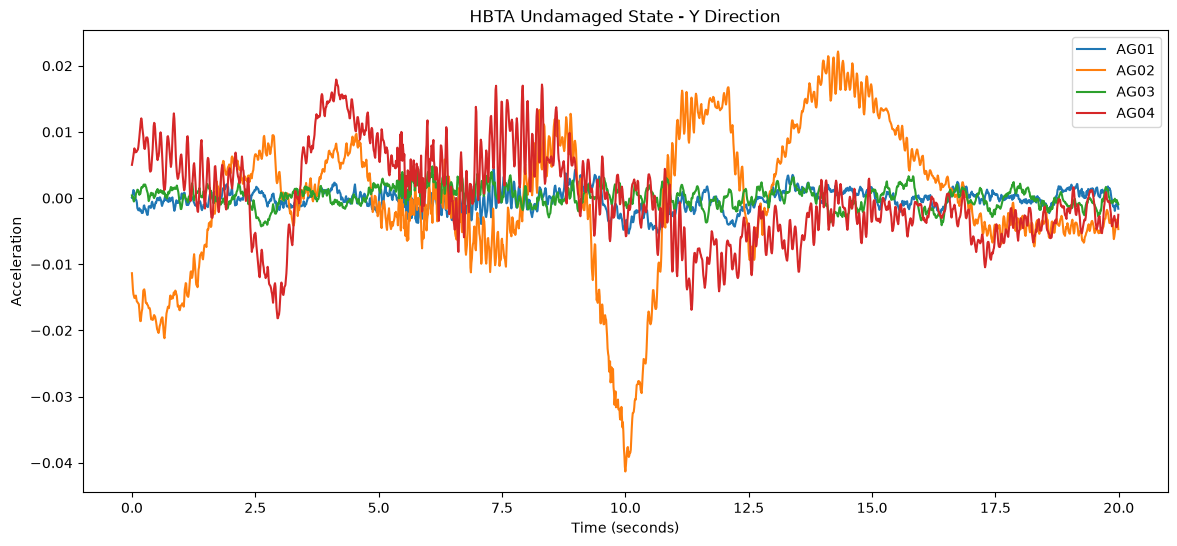

In [36]:
fs = 100
seconds = 20
n = fs * seconds

time = np.arange(n) / fs

plt.figure(figsize=(14, 6))

for i in range(min(4, healthy_data.shape[1])):
    plt.plot(time, healthy_data[:n, i], label=y_sensors[i])

plt.xlabel("Time (seconds)")
plt.ylabel("Acceleration")
plt.title("HBTA Undamaged State - Y Direction")
plt.legend()
plt.show()

In [37]:
print("Shape:", healthy_data.shape)
print("NaN values:", np.isnan(healthy_data).sum())
print("Infinite values:", np.isinf(healthy_data).sum())

print("\nOverall statistics")
print("Minimum:", healthy_data.min())
print("Maximum:", healthy_data.max())
print("Mean:", healthy_data.mean())
print("Standard deviation:", healthy_data.std())


Shape: (62147, 17)
NaN values: 0
Infinite values: 0

Overall statistics
Minimum: -0.8896209286571244
Maximum: 0.8776657379796633
Mean: 4.415639949024936e-08
Standard deviation: 0.07991661908674136


In [38]:
for i, sensor in enumerate(y_sensors):
    print(
        sensor,
        "min =", round(healthy_data[:, i].min(), 6),
        "max =", round(healthy_data[:, i].max(), 6),
        "mean =", round(healthy_data[:, i].mean(), 6),
        "std =", round(healthy_data[:, i].std(), 6)
    )

AG01 min = -0.439633 max = 0.43575 mean = -0.0 std = 0.040187
AG02 min = -0.8321 max = 0.82075 mean = -0.0 std = 0.089179
AG03 min = -0.498074 max = 0.497174 mean = 0.0 std = 0.055831
AG04 min = -0.531829 max = 0.521939 mean = 0.0 std = 0.090463
AG05 min = -0.426851 max = 0.43467 mean = 0.0 std = 0.052403
AG06 min = -0.424549 max = 0.432486 mean = 0.0 std = 0.090225
AG07 min = -0.517485 max = 0.519029 mean = 0.0 std = 0.087835
AG08 min = -0.888602 max = 0.877666 mean = 0.0 std = 0.096848
AG10 min = -0.639063 max = 0.649861 mean = 0.0 std = 0.072297
AG11 min = -0.378329 max = 0.371974 mean = 0.0 std = 0.047634
AG12 min = -0.649876 max = 0.670125 mean = 0.0 std = 0.09616
AG13 min = -0.423071 max = 0.407297 mean = 0.0 std = 0.054209
AG14 min = -0.889621 max = 0.862507 mean = 0.0 std = 0.104189
AG15 min = -0.774185 max = 0.768869 mean = 0.0 std = 0.072483
AG16 min = -0.633647 max = 0.601473 mean = 0.0 std = 0.095269
AG17 min = -0.59271 max = 0.578908 mean = 0.0 std = 0.07199
AG18 min = -0.

In [39]:
n = len(healthy_data)

train_end = int(n * 0.70)
val_end = int(n * 0.85)

train_data = healthy_data[:train_end]
val_data = healthy_data[train_end:val_end]
test_data = healthy_data[val_end:]

print("Training:", train_data.shape)
print("Validation:", val_data.shape)
print("Testing:", test_data.shape)


Training: (43502, 17)
Validation: (9322, 17)
Testing: (9323, 17)


## 2. Data Preprocessing

The HBTA vibration sensor data was prepared for Autoencoder training.

The preprocessing steps included:

1. Selecting 17 accelerometer channels.
2. Checking the data for missing and infinite values.
3. Splitting the healthy measurements into training, validation, and testing sets.
4. Applying StandardScaler to standardise the sensor measurements.
5. Creating fixed-length windows of 500 time steps for model training.

The scaler was fitted using the training data and then applied to the validation and testing data to reduce data leakage.

In [40]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

train_scaled = scaler.fit_transform(train_data)

val_scaled = scaler.transform(val_data)
test_scaled = scaler.transform(test_data)

print("Training mean:", train_scaled.mean())
print("Training std:", train_scaled.std())

print("Train shape:", train_scaled.shape)
print("Validation shape:", val_scaled.shape)
print("Test shape:", test_scaled.shape)

Training mean: -2.1906192785362517e-18
Training std: 1.0000000000000002
Train shape: (43502, 17)
Validation shape: (9322, 17)
Test shape: (9323, 17)


In [41]:
import h5py
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler

# 1. Open HBTA file
file_path = "/Users/sonamtshedon/Downloads/data_100Hz.h5"
h5 = h5py.File(file_path, "r")

# 2. Select healthy measurement
healthy_group = "MVS_P1_UDS_SM_Y_01"

# 3. AG sensors
ag_sensors = [f"AG{i:02d}" for i in range(1, 19)]

# 4. Keep only sensors that have Y-axis data
y_sensors = []

for sensor in ag_sensors:
    if "y" in h5[healthy_group]["acceleration"][sensor].keys():
        y_sensors.append(sensor)

print("Y sensors:", y_sensors)
print("Number of sensors:", len(y_sensors))

# 5. Load Y-axis acceleration
healthy_channels = []

for sensor in y_sensors:
    signal = h5[healthy_group]["acceleration"][sensor]["y"][:]
    healthy_channels.append(signal)

# Make sure all channels have equal length
min_length = min(len(signal) for signal in healthy_channels)

healthy_channels = [
    signal[:min_length]
    for signal in healthy_channels
]

healthy_data = np.column_stack(healthy_channels)

print("Healthy data:", healthy_data.shape)

# 6. Chronological 70/15/15 split
n = len(healthy_data)

train_end = int(n * 0.70)
val_end = int(n * 0.85)

train_data = healthy_data[:train_end]
val_data = healthy_data[train_end:val_end]
test_data = healthy_data[val_end:]

print("Training:", train_data.shape)
print("Validation:", val_data.shape)
print("Testing:", test_data.shape)

print("Setup complete!")

Y sensors: ['AG01', 'AG02', 'AG03', 'AG04', 'AG05', 'AG06', 'AG07', 'AG08', 'AG10', 'AG11', 'AG12', 'AG13', 'AG14', 'AG15', 'AG16', 'AG17', 'AG18']
Number of sensors: 17
Healthy data: (62147, 17)
Training: (43502, 17)
Validation: (9322, 17)
Testing: (9323, 17)
Setup complete!


In [42]:
print(train_data.shape)
print(train_data.dtype)

(43502, 17)
float64


In [43]:
print("test")

test


In [44]:
scaler = StandardScaler()

train_scaled = scaler.fit_transform(train_data)
val_scaled = scaler.transform(val_data)
test_scaled = scaler.transform(test_data)

print("Training mean:", train_scaled.mean())
print("Training std:", train_scaled.std())

print("Train shape:", train_scaled.shape)
print("Validation shape:", val_scaled.shape)
print("Test shape:", test_scaled.shape)

Training mean: -2.1906192785362517e-18
Training std: 1.0000000000000002
Train shape: (43502, 17)
Validation shape: (9322, 17)
Test shape: (9323, 17)


In [45]:
def create_windows(data, window_size=500):
    windows = []

    for start in range(0, len(data) - window_size + 1, window_size):
        end = start + window_size
        windows.append(data[start:end])

    return np.array(windows)

X_train = create_windows(train_scaled)
X_val = create_windows(val_scaled)
X_test = create_windows(test_scaled)

print("X_train:", X_train.shape)
print("X_val:", X_val.shape)
print("X_test:", X_test.shape)

X_train: (87, 500, 17)
X_val: (18, 500, 17)
X_test: (18, 500, 17)


In [46]:
def load_group_y(group_name, sensors):
    channels = []

    for sensor in sensors:
        signal = h5[group_name]["acceleration"][sensor]["y"][:]
        channels.append(signal)

    min_length = min(len(signal) for signal in channels)

    channels = [
        signal[:min_length]
        for signal in channels
    ]

    return np.column_stack(channels)

In [47]:
uds2_raw = load_group_y(
    "MVS_P1_UDS_SM_Y_02",
    y_sensors
)

print("UDS_02 raw shape:", uds2_raw.shape)

UDS_02 raw shape: (61681, 17)


In [48]:
uds2_scaled = scaler.transform(uds2_raw)

X_uds2 = create_windows(uds2_scaled)

print("UDS_02 windows:", X_uds2.shape)

UDS_02 windows: (123, 500, 17)


In [49]:
damage_windows = {}

for i in range(1, 9):

    group_name = f"MVS_P1_DS{i}_SM_Y_01"

    raw_data = load_group_y(
        group_name,
        y_sensors
    )

    scaled_data = scaler.transform(raw_data)

    windows = create_windows(scaled_data)

    damage_windows[f"DS{i}"] = windows

    print(
        f"DS{i}:",
        "raw =", raw_data.shape,
        "windows =", windows.shape
    )

DS1: raw = (62221, 17) windows = (124, 500, 17)
DS2: raw = (62458, 17) windows = (124, 500, 17)
DS3: raw = (62419, 17) windows = (124, 500, 17)
DS4: raw = (62186, 17) windows = (124, 500, 17)
DS5: raw = (62148, 17) windows = (124, 500, 17)
DS6: raw = (62210, 17) windows = (124, 500, 17)
DS7: raw = (62184, 17) windows = (124, 500, 17)
DS8: raw = (62068, 17) windows = (124, 500, 17)


In [50]:
print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)

Training: (87, 500, 17)
Validation: (18, 500, 17)
Testing: (18, 500, 17)


In [51]:
%pip install keras torch



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: pip3 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


## 3. Autoencoder Model Development

### 3.1 Model Architecture

A one-dimensional Convolutional Autoencoder (Conv1D Autoencoder)
was implemented using TensorFlow and Keras.

The model architecture was adapted from the Keras time-series
anomaly detection example.

The encoder uses Conv1D layers to compress the input sensor
measurements into a lower-dimensional representation.

The decoder uses Conv1DTranspose layers to reconstruct the
original sensor measurements.

The model takes an input window of 500 time steps and 17 sensor
channels and produces a reconstructed window of the same shape.

### 3.2 Model Training

The Autoencoder was trained using healthy HBTA sensor measurements.

Mean Squared Error (MSE) was used as the loss function, and
the Adam optimiser was used to update the model weights.

Training was configured for up to 50 epochs, with early stopping
to monitor validation loss.

The purpose of training was to learn normal vibration patterns
so that reconstruction errors could subsequently be evaluated
for healthy and damaged conditions.

In [52]:
import os
os.environ["KERAS_BACKEND"] = "torch"

import keras
from keras import layers

print("Keras version:", keras.__version__)
print("Backend:", keras.backend.backend())

Keras version: 3.16.0.dev2026101904
Backend: torch


In [53]:
# Adapted from the official Keras Time Series
# Anomaly Detection Using an Autoencoder example

import keras
from keras import layers

model = keras.Sequential([
    layers.Input(shape=(500, 17)),

    # Encoder
    layers.Conv1D(
        filters=32,
        kernel_size=7,
        padding="same",
        strides=2,
        activation="relu"
    ),
    layers.Dropout(rate=0.2),

    layers.Conv1D(
        filters=16,
        kernel_size=7,
        padding="same",
        strides=2,
        activation="relu"
    ),

    # Decoder
    layers.Conv1DTranspose(
        filters=16,
        kernel_size=7,
        padding="same",
        strides=2,
        activation="relu"
    ),
    layers.Dropout(rate=0.2),

    layers.Conv1DTranspose(
        filters=32,
        kernel_size=7,
        padding="same",
        strides=2,
        activation="relu"
    ),

    layers.Conv1DTranspose(
        filters=17,
        kernel_size=7,
        padding="same"
    ),

])

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="mse"
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 250, 32)        │         3,840 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 250, 32)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 125, 16)        │         3,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_transpose                │ (None, 250, 16)        │         1,808 │
│ (Conv1DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 250, 16)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_transpose_1              │ (None, 500, 32)        │         3,616 │
│ (Conv1DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_transpose_2              │ (None, 500, 17)        │         3,825 │
│ (Conv1DTranspose)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 16,689 (65.19 KB)

 Trainable params: 16,689 (65.19 KB)

 Non-trainable params: 0 (0.00 B)

In [54]:
print("Model output:", model.output_shape)

Model output: (None, 500, 17)


In [55]:
import numpy as np
import keras

# Ensure data is in the correct format
X_train_ae = np.asarray(X_train, dtype=np.float32)
X_val_ae = np.asarray(X_val, dtype=np.float32)

# Check input and output shapes
print("Training:", X_train_ae.shape)
print("Validation:", X_val_ae.shape)
print("Model output:", model.output_shape)

# Train on healthy vibration data
history = model.fit(
    X_train_ae,
    X_train_ae,
    validation_data=(X_val_ae, X_val_ae),
    epochs=50,
    batch_size=8,
    shuffle=True,
    callbacks=[
        keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=8,
            restore_best_weights=True
        )
    ],
    verbose=1
)

Training: (87, 500, 17)
Validation: (18, 500, 17)
Model output: (None, 500, 17)
Epoch 1/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 26ms/step - loss: 1.0016 - val_loss: 1.4827
Epoch 2/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 0.9791 - val_loss: 1.4436
Epoch 3/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 0.9196 - val_loss: 1.3419
Epoch 4/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 0.8080 - val_loss: 1.2487
Epoch 5/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 0.7172 - val_loss: 1.1210
Epoch 6/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 0.6484 - val_loss: 0.9202
Epoch 7/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 0.6004 - val_loss: 0.8053
Epoch 8/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 0.5632 - val_loss: 0.7424
Epoch 9/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 0.5271 - val_loss: 0.6725
Epoch 10/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 0.5057 - val_loss: 0.6072
Epoch 11/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 0.4831 - 

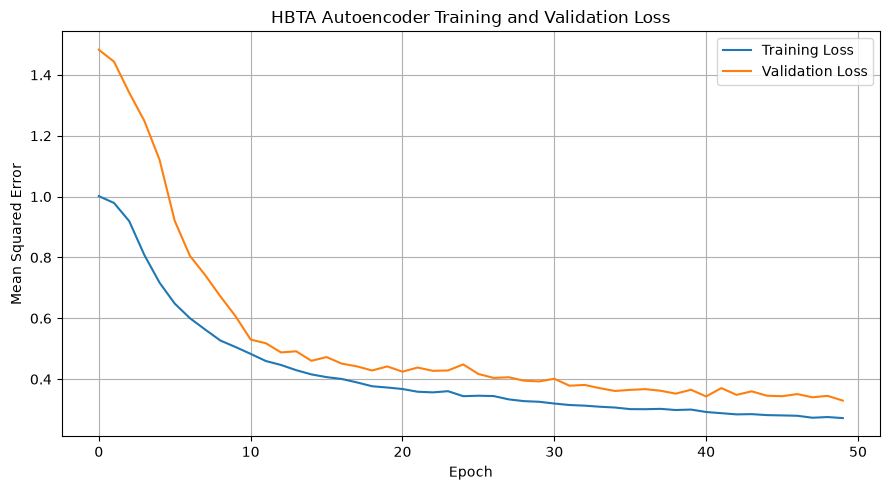

In [56]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error")
plt.title("HBTA Autoencoder Training and Validation Loss")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [57]:
import numpy as np

X_test_ae = np.asarray(X_test, dtype=np.float32)

# Reconstruct healthy test signals
X_test_pred = model.predict(X_test_ae)

# Calculate reconstruction error for each window
healthy_errors = np.mean(
    (X_test_ae - X_test_pred) ** 2,
    axis=(1, 2)
)

print("Healthy test windows:", len(healthy_errors))
print("Average reconstruction error:", healthy_errors.mean())
print("Minimum error:", healthy_errors.min())
print("Maximum error:", healthy_errors.max())

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step
Healthy test windows: 18
Average reconstruction error: 0.02041817
Minimum error: 0.005130854
Maximum error: 0.089168556


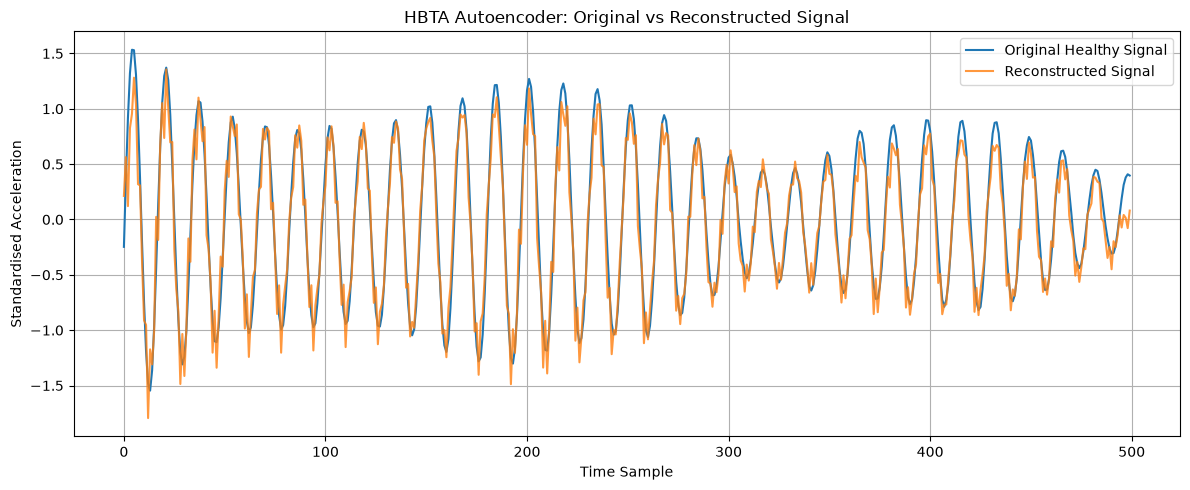

In [58]:
import matplotlib.pyplot as plt

window_index = 0
sensor_index = 0

plt.figure(figsize=(12, 5))

plt.plot(
    X_test_ae[window_index, :, sensor_index],
    label="Original Healthy Signal"
)

plt.plot(
    X_test_pred[window_index, :, sensor_index],
    label="Reconstructed Signal",
    alpha=0.8
)

plt.xlabel("Time Sample")
plt.ylabel("Standardised Acceleration")
plt.title("HBTA Autoencoder: Original vs Reconstructed Signal")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [59]:
print("Damage data type:", type(damage_windows))

if isinstance(damage_windows, dict):
    for condition, windows in damage_windows.items():
        print(condition, np.asarray(windows).shape)
else:
    print("Damage data shape:", np.asarray(damage_windows).shape)

Damage data type: <class 'dict'>
DS1 (124, 500, 17)
DS2 (124, 500, 17)
DS3 (124, 500, 17)
DS4 (124, 500, 17)
DS5 (124, 500, 17)
DS6 (124, 500, 17)
DS7 (124, 500, 17)
DS8 (124, 500, 17)


In [60]:
import numpy as np

damage_errors = {}

for condition, windows in damage_windows.items():

    X_damage = np.asarray(windows, dtype=np.float32)

    # Reconstruct damaged vibration signals
    X_reconstructed = model.predict(X_damage, verbose=0)

    # Calculate mean squared reconstruction error
    errors = np.mean(
        (X_damage - X_reconstructed) ** 2,
        axis=(1, 2)
    )

    damage_errors[condition] = errors

    print(
        f"{condition}: "
        f"Mean error = {errors.mean():.6f}, "
        f"Max error = {errors.max():.6f}"
    )

DS1: Mean error = 0.309046, Max error = 3.599950
DS2: Mean error = 0.234543, Max error = 1.442179
DS3: Mean error = 0.234254, Max error = 1.636868
DS4: Mean error = 0.223525, Max error = 1.413413
DS5: Mean error = 0.331895, Max error = 7.069734
DS6: Mean error = 0.279830, Max error = 2.045584
DS7: Mean error = 0.362975, Max error = 3.235890
DS8: Mean error = 0.344584, Max error = 2.741941


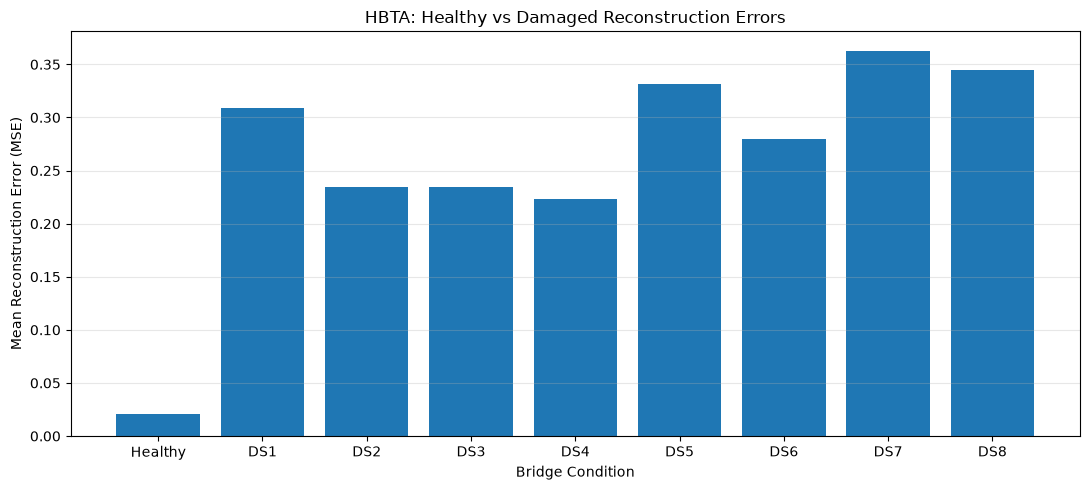

In [61]:
import matplotlib.pyplot as plt

labels = ["Healthy"]
values = [healthy_errors.mean()]

for condition, errors in damage_errors.items():
    labels.append(condition)
    values.append(errors.mean())

plt.figure(figsize=(11, 5))

plt.bar(labels, values)

plt.xlabel("Bridge Condition")
plt.ylabel("Mean Reconstruction Error (MSE)")
plt.title("HBTA: Healthy vs Damaged Reconstruction Errors")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [62]:
# Reconstruct healthy validation windows
val_pred = model.predict(X_val_ae, verbose=0)

# Reconstruction error for each validation window
val_errors = np.mean(
    (X_val_ae - val_pred) ** 2,
    axis=(1, 2)
)

# Initial threshold: 95th percentile
threshold = np.percentile(val_errors, 95)

print("Anomaly detection threshold:", threshold)

Anomaly detection threshold: 0.94419014


In [63]:
# Percentage of healthy test windows flagged as damaged
healthy_false_positive_rate = np.mean(
    healthy_errors > threshold
) * 100

print(
    f"Healthy false positive rate: "
    f"{healthy_false_positive_rate:.2f}%"
)

print("\nDamage detection rates:")

for condition, errors in damage_errors.items():
    detection_rate = np.mean(errors > threshold) * 100

    print(
        f"{condition}: {detection_rate:.2f}%"
    )

Healthy false positive rate: 0.00%

Damage detection rates:
DS1: 9.68%
DS2: 6.45%
DS3: 5.65%
DS4: 5.65%
DS5: 6.45%
DS6: 6.45%
DS7: 12.10%
DS8: 11.29%


In [64]:
print("Healthy validation reconstruction errors:")
print(np.sort(val_errors))

print("\nValidation statistics:")
print("Mean:", np.mean(val_errors))
print("Median:", np.median(val_errors))
print("Minimum:", np.min(val_errors))
print("Maximum:", np.max(val_errors))

print("\nHealthy test statistics:")
print("Mean:", np.mean(healthy_errors))
print("Median:", np.median(healthy_errors))
print("Maximum:", np.max(healthy_errors))

Healthy validation reconstruction errors:
[0.02784615 0.0573781  0.07641958 0.07726947 0.09641344 0.10356449
 0.13944368 0.14367563 0.2040745  0.23469965 0.2843456  0.35220242
 0.3835828  0.389935   0.58423215 0.74340224 0.9132514  1.1195097 ]

Validation statistics:
Mean: 0.32951367
Median: 0.21938708
Minimum: 0.027846148
Maximum: 1.1195097

Healthy test statistics:
Mean: 0.02041817
Median: 0.012800041
Maximum: 0.089168556


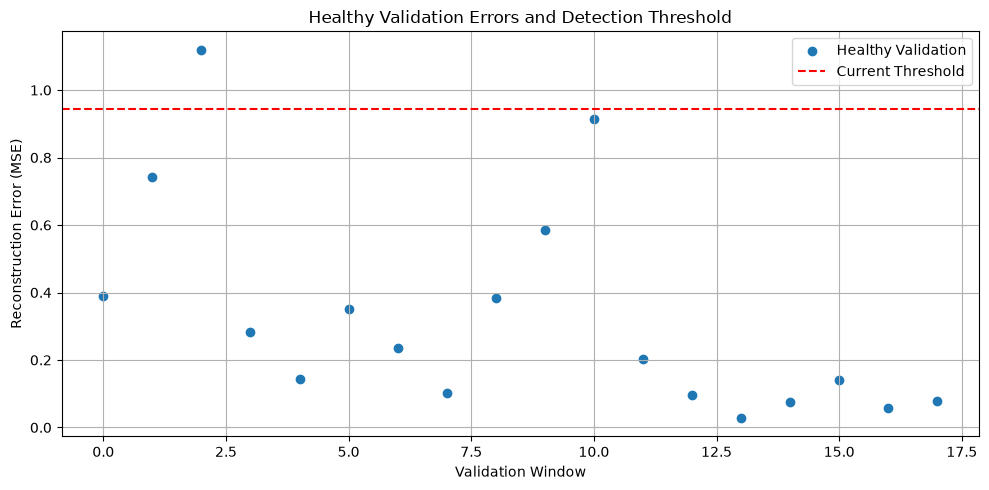

In [65]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.scatter(
    range(len(val_errors)),
    val_errors,
    label="Healthy Validation",
    marker="o"
)

plt.axhline(
    threshold,
    color="red",
    linestyle="--",
    label="Current Threshold"
)

plt.xlabel("Validation Window")
plt.ylabel("Reconstruction Error (MSE)")
plt.title("Healthy Validation Errors and Detection Threshold")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

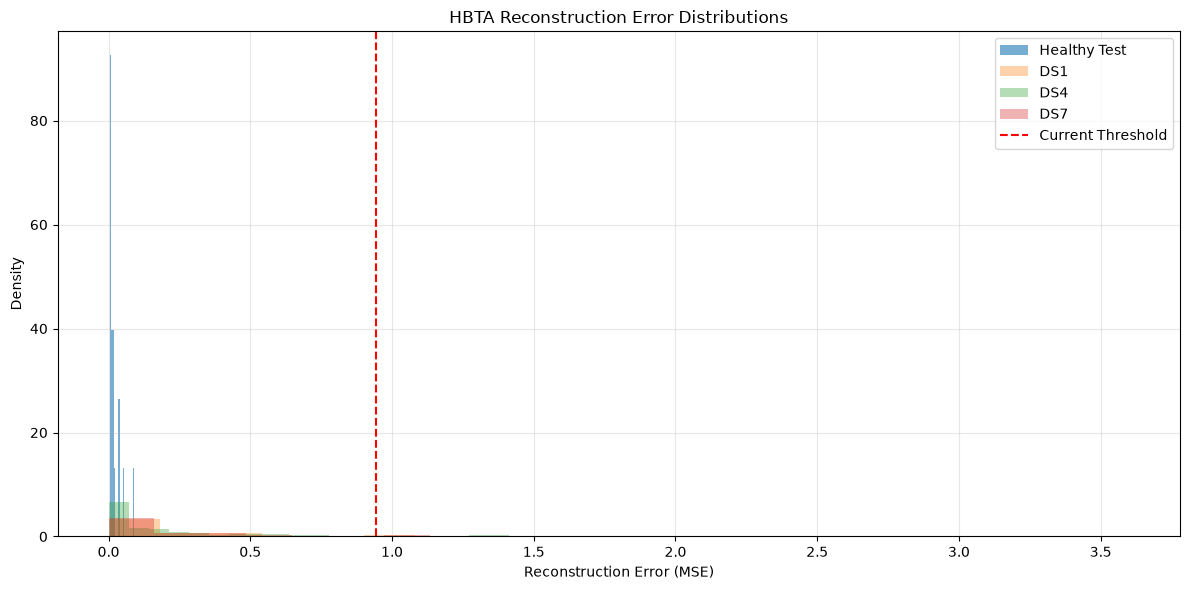

In [66]:
import matplotlib.pyplot as plt
import numpy as np

plt.figure(figsize=(12, 6))

plt.hist(
    healthy_errors,
    bins=20,
    alpha=0.6,
    label="Healthy Test",
    density=True
)

for condition in ["DS1", "DS4", "DS7"]:
    plt.hist(
        damage_errors[condition],
        bins=20,
        alpha=0.35,
        label=condition,
        density=True
    )

plt.axvline(
    threshold,
    color="red",
    linestyle="--",
    label="Current Threshold"
)

plt.xlabel("Reconstruction Error (MSE)")
plt.ylabel("Density")
plt.title("HBTA Reconstruction Error Distributions")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [67]:
for percentile in [50, 75, 90, 95, 99]:
    value = np.percentile(val_errors, percentile)
    print(f"{percentile}th percentile: {value:.6f}")

50th percentile: 0.219387
75th percentile: 0.388347
90th percentile: 0.794357
95th percentile: 0.944190
99th percentile: 1.084446


In [68]:
import numpy as np

# Prepare the second undamaged recording
X_uds2_ae = np.asarray(X_uds2, dtype=np.float32)

print("Second undamaged data shape:", X_uds2_ae.shape)

# Reconstruct signals
uds2_pred = model.predict(X_uds2_ae, verbose=0)

# Calculate reconstruction error
uds2_errors = np.mean(
    (X_uds2_ae - uds2_pred) ** 2,
    axis=(1, 2)
)

print("Mean error:", uds2_errors.mean())
print("Median error:", np.median(uds2_errors))
print("Maximum error:", uds2_errors.max())

# Evaluate using the existing threshold
uds2_false_positive_rate = np.mean(
    uds2_errors > threshold
) * 100

print(f"False positive rate: {uds2_false_positive_rate:.2f}%")

Second undamaged data shape: (123, 500, 17)
Mean error: 0.22535448
Median error: 0.08349014
Maximum error: 1.5929047
False positive rate: 5.69%


In [69]:
import numpy as np
import pandas as pd

# Exploratory threshold comparison
percentiles = [50, 75, 90, 95, 99]

results = []

for p in percentiles:
    t = np.percentile(val_errors, p)

    row = {
        "Percentile": p,
        "Threshold": round(float(t), 4),
        "Healthy Test FPR (%)": round(
            float(np.mean(healthy_errors > t) * 100), 2
        ),
        "UDS2 FPR (%)": round(
            float(np.mean(uds2_errors > t) * 100), 2
        )
    }

    for condition, errors in damage_errors.items():
        row[condition + " Detection (%)"] = round(
            float(np.mean(errors > t) * 100), 2
        )

    results.append(row)

results_df = pd.DataFrame(results)

display(results_df)

,Percentile,Threshold,Healthy Test FPR (%),UDS2 FPR (%),DS1 Detection (%),DS2 Detection (%),DS3 Detection (%),DS4 Detection (%),DS5 Detection (%),DS6 Detection (%),DS7 Detection (%),DS8 Detection (%)
0,50,0.2194,0.0,34.15,37.90,35.48,33.87,30.65,29.84,34.68,38.71,41.13
1,75,0.3883,0.0,20.33,25.00,21.77,20.16,20.16,21.77,24.19,27.42,32.26
2,90,0.7944,0.0,5.69,12.10,7.26,8.06,6.45,6.45,9.68,14.52,12.90
3,95,0.9442,0.0,5.69,9.68,6.45,5.65,5.65,6.45,6.45,12.10,11.29
4,99,1.0844,0.0,4.07,6.45,4.03,4.84,4.03,6.45,6.45,8.87,8.87


In [70]:
print("Training shape:", X_train.shape)
print("UDS2 shape:", X_uds2.shape)

for condition, windows in damage_windows.items():
    print(condition, np.asarray(windows).shape)

print("\nScaler information:")
print("Number of features:", scaler.n_features_in_)
print("Scaler mean:", scaler.mean_)
print("Scaler standard deviation:", scaler.scale_)

Training shape: (87, 500, 17)
UDS2 shape: (123, 500, 17)
DS1 (124, 500, 17)
DS2 (124, 500, 17)
DS3 (124, 500, 17)
DS4 (124, 500, 17)
DS5 (124, 500, 17)
DS6 (124, 500, 17)
DS7 (124, 500, 17)
DS8 (124, 500, 17)

Scaler information:
Number of features: 17
Scaler mean: [ 4.62122003e-05 -4.28041504e-05  1.35402968e-05  9.16056470e-05
 -1.20206120e-05 -9.75226320e-05  5.45213312e-06 -3.14101880e-06
  2.61185321e-05 -2.72555840e-05  1.19385301e-04 -1.62871234e-05
  1.93172543e-05 -4.13823761e-05 -2.24028163e-05 -6.31041049e-05
  5.46172799e-05]
Scaler standard deviation: [0.0438476  0.08159875 0.05330801 0.08371251 0.05500682 0.08577567
 0.09673563 0.08992788 0.07265196 0.04573449 0.0881039  0.05345578
 0.09854496 0.07855462 0.0914098  0.07855793 0.10086427]


In [71]:
import numpy as np

datasets = {
    "Healthy Train": X_train,
    "Healthy Validation": X_val,
    "Healthy Test": X_test,
    "UDS2": X_uds2,
    **damage_windows
}

for name, data in datasets.items():
    data = np.asarray(data)

    print(
        f"{name:20s}"
        f"Mean absolute value: {np.mean(np.abs(data)):.4f}  "
        f"Standard deviation: {np.std(data):.4f}"
    )

Healthy Train       Mean absolute value: 0.5579  Standard deviation: 1.0000
Healthy Validation  Mean absolute value: 0.7798  Standard deviation: 1.2219
Healthy Test        Mean absolute value: 0.4196  Standard deviation: 0.7192
UDS2                Mean absolute value: 0.5946  Standard deviation: 1.0645
DS1                 Mean absolute value: 0.5965  Standard deviation: 1.0715
DS2                 Mean absolute value: 0.5733  Standard deviation: 1.0230
DS3                 Mean absolute value: 0.5723  Standard deviation: 1.0370
DS4                 Mean absolute value: 0.5580  Standard deviation: 1.0113
DS5                 Mean absolute value: 0.5410  Standard deviation: 1.0093
DS6                 Mean absolute value: 0.5791  Standard deviation: 1.0348
DS7                 Mean absolute value: 0.6015  Standard deviation: 1.0857
DS8                 Mean absolute value: 0.5829  Standard deviation: 1.0472


## 4. Model Validation and Evaluation

### 4.1 Reconstruction Error

The trained Autoencoder was evaluated using healthy and
damaged HBTA sensor measurements.

Reconstruction error was calculated using Mean Squared Error
(MSE) between the original sensor windows and the
Autoencoder's reconstructed outputs.

Higher reconstruction errors may indicate unusual vibration
patterns, although they do not necessarily confirm damage.

### 4.2 ROC-AUC Evaluation

The model was evaluated across eight damage conditions
(DS1 to DS8) using ROC-AUC.

ROC-AUC measures how well reconstruction errors distinguish
damaged sensor windows from healthy sensor windows.

A score of 0.5 indicates performance equivalent to random
ranking, while a score of 1.0 indicates perfect separation.

### 4.3 Model Comparison

The baseline and second Autoencoder configurations were
compared using their ROC-AUC scores.

The average ROC-AUC scores were approximately:

- Baseline Autoencoder: 0.5151
- Second Autoencoder: 0.5150

Both configurations demonstrated limited ability to
distinguish healthy and damaged conditions.

The results suggest that reconstruction error alone,
under the current experimental setup, was insufficient
for reliable damage detection.

In [72]:
import numpy as np
from sklearn.metrics import roc_auc_score

auc_results = {}

for condition, errors in damage_errors.items():

    # Undamaged = 0, Damaged = 1
    labels = np.concatenate([
        np.zeros(len(uds2_errors)),
        np.ones(len(errors))
    ])

    scores = np.concatenate([
        uds2_errors,
        errors
    ])

    auc = roc_auc_score(labels, scores)
    auc_results[condition] = auc

    print(f"{condition}: ROC-AUC = {auc:.4f}")

DS1: ROC-AUC = 0.5467
DS2: ROC-AUC = 0.5224
DS3: ROC-AUC = 0.4961
DS4: ROC-AUC = 0.4957
DS5: ROC-AUC = 0.4814
DS6: ROC-AUC = 0.5069
DS7: ROC-AUC = 0.5148
DS8: ROC-AUC = 0.5697


Total healthy windows: 123
Minimum RMS: 0.041879782800271166
Median RMS: 0.6167705141155395
Maximum RMS: 3.0000985823750996


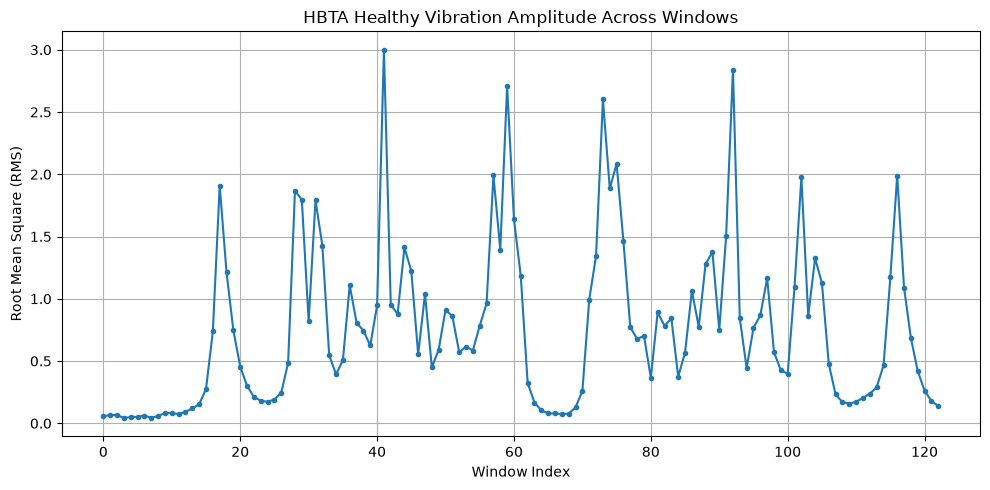

In [73]:
import numpy as np
import matplotlib.pyplot as plt

# Combine the original healthy windows
all_healthy = np.concatenate(
    [X_train, X_val, X_test],
    axis=0
)

# Calculate signal amplitude for each window
window_rms = np.sqrt(
    np.mean(all_healthy ** 2, axis=(1, 2))
)

print("Total healthy windows:", len(all_healthy))
print("Minimum RMS:", window_rms.min())
print("Median RMS:", np.median(window_rms))
print("Maximum RMS:", window_rms.max())

plt.figure(figsize=(10, 5))
plt.plot(window_rms, marker="o", markersize=3)
plt.xlabel("Window Index")
plt.ylabel("Root Mean Square (RMS)")
plt.title("HBTA Healthy Vibration Amplitude Across Windows")
plt.grid(True)
plt.tight_layout()
plt.show()

Spearman correlation: 0.7995
P-value: 0.000000


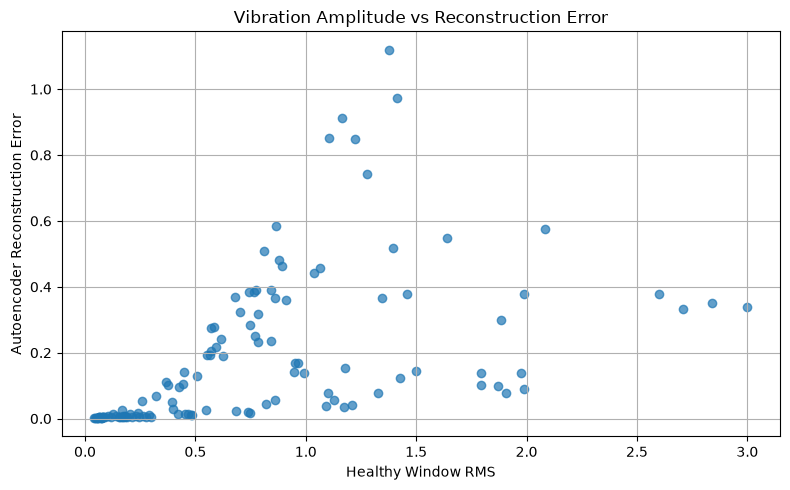

In [74]:
from scipy.stats import spearmanr
import matplotlib.pyplot as plt
import numpy as np

# Combine errors from the existing healthy datasets
train_pred = model.predict(
    np.asarray(X_train, dtype=np.float32),
    verbose=0
)

train_errors = np.mean(
    (X_train - train_pred) ** 2,
    axis=(1, 2)
)

all_healthy_errors = np.concatenate([
    train_errors,
    val_errors,
    healthy_errors
])

# Check the relationship
correlation, p_value = spearmanr(
    window_rms,
    all_healthy_errors
)

print(f"Spearman correlation: {correlation:.4f}")
print(f"P-value: {p_value:.6f}")

plt.figure(figsize=(8, 5))
plt.scatter(window_rms, all_healthy_errors, alpha=0.7)
plt.xlabel("Healthy Window RMS")
plt.ylabel("Autoencoder Reconstruction Error")
plt.title("Vibration Amplitude vs Reconstruction Error")
plt.grid(True)
plt.tight_layout()
plt.show()

In [75]:
from sklearn.metrics import roc_auc_score
import numpy as np

def relative_reconstruction_errors(windows):
    windows = np.asarray(windows, dtype=np.float32)

    predictions = model.predict(windows, verbose=0)

    mse = np.mean(
        (windows - predictions) ** 2,
        axis=(1, 2)
    )

    signal_energy = np.mean(
        windows ** 2,
        axis=(1, 2)
    )

    return mse / (signal_energy + 1e-8)


# Calculate relative errors for undamaged recording
uds2_relative = relative_reconstruction_errors(X_uds2)

# Compare against damaged conditions
for condition, windows in damage_windows.items():

    damaged_relative = relative_reconstruction_errors(windows)

    labels = np.concatenate([
        np.zeros(len(uds2_relative)),
        np.ones(len(damaged_relative))
    ])

    scores = np.concatenate([
        uds2_relative,
        damaged_relative
    ])

    auc = roc_auc_score(labels, scores)

    print(f"{condition}: Relative-error ROC-AUC = {auc:.4f}")

DS1: Relative-error ROC-AUC = 0.5348
DS2: Relative-error ROC-AUC = 0.5117
DS3: Relative-error ROC-AUC = 0.5089
DS4: Relative-error ROC-AUC = 0.5172
DS5: Relative-error ROC-AUC = 0.5035
DS6: Relative-error ROC-AUC = 0.5229
DS7: Relative-error ROC-AUC = 0.5172
DS8: Relative-error ROC-AUC = 0.5763


In [76]:
# Save the trained baseline Autoencoder
model.save("hbta_conv1d_autoencoder_baseline.keras")

print("Baseline model saved successfully!")

Baseline model saved successfully!


In [77]:
import numpy as np

# Combine the healthy windows from UDS1
healthy_windows = np.concatenate(
    [X_train, X_val, X_test],
    axis=0
).astype(np.float32)

# Use the first 80% for training
split_index = int(len(healthy_windows) * 0.80)

X_train_new = healthy_windows[:split_index]
X_val_new = healthy_windows[split_index:]

print("New training shape:", X_train_new.shape)
print("New validation shape:", X_val_new.shape)

New training shape: (98, 500, 17)
New validation shape: (25, 500, 17)


In [78]:
from sklearn.preprocessing import StandardScaler
import numpy as np

# Convert the existing standardised data back to raw values
train_raw_new = scaler.inverse_transform(
    X_train_new.reshape(-1, 17)
)

val_raw_new = scaler.inverse_transform(
    X_val_new.reshape(-1, 17)
)

# Fit a new scaler using ONLY the new training data
scaler_new = StandardScaler()

train_scaled_new = scaler_new.fit_transform(
    train_raw_new
)

val_scaled_new = scaler_new.transform(
    val_raw_new
)

# Restore the window shapes
X_train_new = train_scaled_new.reshape(-1, 500, 17).astype(np.float32)
X_val_new = val_scaled_new.reshape(-1, 500, 17).astype(np.float32)

print("Training:", X_train_new.shape)
print("Validation:", X_val_new.shape)
print("New scaler features:", scaler_new.n_features_in_)

Training: (98, 500, 17)
Validation: (25, 500, 17)
New scaler features: 17


In [79]:
import keras

# Load the saved architecture and initialise fresh weights
model_improved = keras.models.clone_model(model)

model_improved.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="mse"
)

# Train using the new healthy dataset
history_improved = model_improved.fit(
    X_train_new,
    X_train_new,
    validation_data=(X_val_new, X_val_new),
    epochs=50,
    batch_size=8,
    shuffle=True,
    callbacks=[
        keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=8,
            restore_best_weights=True
        )
    ],
    verbose=1
)

print("Improved model training completed!")

Epoch 1/50
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - loss: 1.0042 - val_loss: 0.6686
Epoch 2/50
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 0.9835 - val_loss: 0.6493
Epoch 3/50
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - loss: 0.9159 - val_loss: 0.5822
Epoch 4/50
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - loss: 0.7778 - val_loss: 0.4990
Epoch 5/50
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 0.6557 - val_loss: 0.4334
Epoch 6/50
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - loss: 0.5972 - val_loss: 0.3592
Epoch 7/50
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 0.5626 - val_loss: 0.3254
Epoch 8/50
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - loss: 0.5301 - val_loss: 0.2778
Epoch 9/50
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 0.5144 - val_loss: 0.2398
Epoch 10/50
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - loss: 0.4869 - val_loss: 0.1874
Epoch 11/50
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 0.4675 - val_loss: 0.1542
Epoch 12/50
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 0.4

In [80]:
import numpy as np
from sklearn.metrics import roc_auc_score

def transform_for_improved_model(windows):
    windows = np.asarray(windows, dtype=np.float32)
    shape = windows.shape

    # Reverse the original scaling
    original_values = scaler.inverse_transform(
        windows.reshape(-1, 17)
    )

    # Apply the improved model's scaler
    new_values = scaler_new.transform(original_values)

    return new_values.reshape(shape).astype(np.float32)


def improved_reconstruction_error(windows):
    prepared = transform_for_improved_model(windows)

    reconstructed = model_improved.predict(
        prepared, verbose=0
    )

    return np.mean(
        (prepared - reconstructed) ** 2,
        axis=(1, 2)
    )


# Evaluate the second undamaged recording
uds2_errors_improved = improved_reconstruction_error(X_uds2)

# Evaluate each damaged condition
auc_improved = {}

for condition, windows in damage_windows.items():

    damaged_errors = improved_reconstruction_error(windows)

    labels = np.concatenate([
        np.zeros(len(uds2_errors_improved)),
        np.ones(len(damaged_errors))
    ])

    scores = np.concatenate([
        uds2_errors_improved,
        damaged_errors
    ])

    auc = roc_auc_score(labels, scores)

    auc_improved[condition] = auc

    print(f"{condition}: Improved ROC-AUC = {auc:.4f}")

print(
    "\nAverage improved ROC-AUC:",
    round(np.mean(list(auc_improved.values())), 4)
)

DS1: Improved ROC-AUC = 0.5393
DS2: Improved ROC-AUC = 0.5178
DS3: Improved ROC-AUC = 0.4952
DS4: Improved ROC-AUC = 0.4946
DS5: Improved ROC-AUC = 0.4822
DS6: Improved ROC-AUC = 0.5047
DS7: Improved ROC-AUC = 0.5133
DS8: Improved ROC-AUC = 0.5611

Average improved ROC-AUC: 0.5135


In [81]:
import pandas as pd
import numpy as np
import joblib

# Save improved Autoencoder and its scaler
model_improved.save("hbta_conv1d_autoencoder_improved.keras")
joblib.dump(scaler_new, "hbta_scaler_improved.pkl")

# Compare model results
comparison = pd.DataFrame({
    "Condition": list(auc_improved.keys()),
    "Baseline_ROC_AUC": [
        auc_results[c] for c in auc_improved
    ],
    "Improved_ROC_AUC": [
        auc_improved[c] for c in auc_improved
    ]
})

comparison.to_csv("hbta_model_comparison.csv", index=False)

print(comparison.round(4))
print("\nFiles saved successfully!")

  Condition  Baseline_ROC_AUC  Improved_ROC_AUC
0       DS1            0.5467            0.5393
1       DS2            0.5224            0.5178
2       DS3            0.4961            0.4952
3       DS4            0.4957            0.4946
4       DS5            0.4814            0.4822
5       DS6            0.5069            0.5047
6       DS7            0.5148            0.5133
7       DS8            0.5697            0.5611

Files saved successfully!


In [82]:
import tensorflow as tf
import keras

print("TensorFlow:", tf.__version__)

model_improved = keras.models.load_model(
    "hbta_conv1d_autoencoder_improved.keras"
)

model_improved.summary()

TensorFlow: 2.22.0-rc0


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 250, 32)        │         3,840 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 250, 32)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 125, 16)        │         3,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_transpose                │ (None, 250, 16)        │         1,808 │
│ (Conv1DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 250, 16)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_transpose_1              │ (None, 500, 32)        │         3,616 │
│ (Conv1DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_transpose_2              │ (None, 500, 17)        │         3,825 │
│ (Conv1DTranspose)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 50,069 (195.58 KB)

 Trainable params: 16,689 (65.19 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 33,380 (130.39 KB)

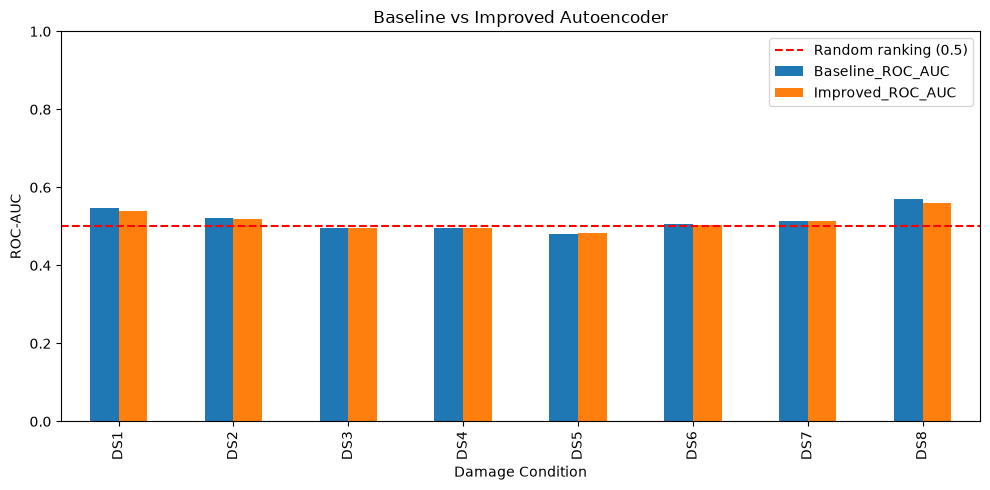

In [83]:
import pandas as pd
import matplotlib.pyplot as plt

comparison = pd.read_csv("hbta_model_comparison.csv")

comparison.plot(
    x="Condition",
    y=["Baseline_ROC_AUC", "Improved_ROC_AUC"],
    kind="bar",
    figsize=(10, 5)
)

plt.axhline(0.5, color="red", linestyle="--",
            label="Random ranking (0.5)")
plt.title("Baseline vs Improved Autoencoder")
plt.ylabel("ROC-AUC")
plt.xlabel("Damage Condition")
plt.ylim(0, 1)
plt.legend()
plt.tight_layout()
plt.savefig("hbta_model_comparison.png", dpi=300)
plt.show()

In [84]:
for name in ["scaler", "uds2_raw", "create_windows"]:
    print(name, "READY" if name in globals() else "MISSING")

scaler READY
uds2_raw READY
create_windows READY


In [85]:
import json
from pathlib import Path

notebook = Path.home() / "HBTA-1.ipynb"

with open(notebook, encoding="utf-8") as f:
    data = json.load(f)

keywords = [
    "StandardScaler",
    "scaler",
    "uds2_raw",
    "create_windows",
    "damage_windows"
]

for i, cell in enumerate(data["cells"], start=1):
    source = "".join(cell.get("source", []))

    if any(word in source for word in keywords):
        print(f"\n--- Cell {i} ---")
        print(source[:1500])


--- Cell 22 ---
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

train_scaled = scaler.fit_transform(train_data)

val_scaled = scaler.transform(val_data)
test_scaled = scaler.transform(test_data)

print("Training mean:", train_scaled.mean())
print("Training std:", train_scaled.std())

print("Train shape:", train_scaled.shape)
print("Validation shape:", val_scaled.shape)
print("Test shape:", test_scaled.shape)

--- Cell 23 ---
import h5py
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler

# 1. Open HBTA file
file_path = "/Users/sonamtshedon/Downloads/data_100Hz.h5"
h5 = h5py.File(file_path, "r")

# 2. Select healthy measurement
healthy_group = "MVS_P1_UDS_SM_Y_01"

# 3. AG sensors
ag_sensors = [f"AG{i:02d}" for i in range(1, 19)]

# 4. Keep only sensors that have Y-axis data
y_sensors = []

for sensor in ag_sensors:
    if "y" in h5[healthy_group]["acceleration"][sensor].keys():
        y_sensors.append(senso

In [86]:
print("train_data:", "READY" if "train_data" in globals() else "MISSING")

train_data: READY


In [87]:
for name in [
    "model_improved",
    "scaler",
    "scaler_new",
    "X_uds2",
    "damage_windows",
    "improved_reconstruction_error"
]:
    print(name, "READY" if name in globals() else "MISSING")

model_improved READY
scaler READY
scaler_new READY
X_uds2 READY
damage_windows READY
improved_reconstruction_error READY


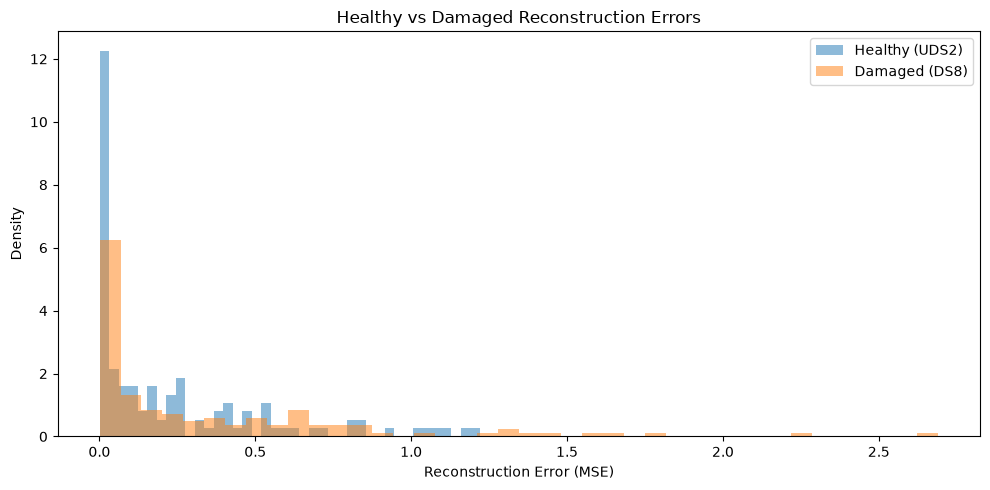

In [88]:
import numpy as np
import matplotlib.pyplot as plt

healthy_errors = improved_reconstruction_error(X_uds2)
damaged_errors = improved_reconstruction_error(
    damage_windows["DS8"]
)

plt.figure(figsize=(10, 5))

plt.hist(
    healthy_errors,
    bins=40,
    alpha=0.5,
    density=True,
    label="Healthy (UDS2)"
)

plt.hist(
    damaged_errors,
    bins=40,
    alpha=0.5,
    density=True,
    label="Damaged (DS8)"
)

plt.xlabel("Reconstruction Error (MSE)")
plt.ylabel("Density")
plt.title("Healthy vs Damaged Reconstruction Errors")
plt.legend()
plt.tight_layout()
plt.show()

In [89]:
from pathlib import Path

home = Path.home()

files = [
    "hbta_conv1d_autoencoder_baseline.keras",
    "hbta_conv1d_autoencoder_improved.keras",
    "hbta_scaler_improved.pkl",
    "hbta_model_comparison.csv"
]

for filename in files:
    path = home / filename

    if path.exists():
        print(f"FOUND: {filename}")
    else:
        print(f"NOT FOUND: {filename}")

FOUND: hbta_conv1d_autoencoder_baseline.keras
FOUND: hbta_conv1d_autoencoder_improved.keras
FOUND: hbta_scaler_improved.pkl
FOUND: hbta_model_comparison.csv


In [90]:
import pandas as pd
from pathlib import Path

results = pd.read_csv(
    Path.home() / "hbta_model_comparison.csv"
)

print("Column names:")
print(results.columns.tolist())

print("\nSaved results:")
print(results.to_string(index=False))

Column names:
['Condition', 'Baseline_ROC_AUC', 'Improved_ROC_AUC']

Saved results:
Condition  Baseline_ROC_AUC  Improved_ROC_AUC
      DS1          0.546748          0.539274
      DS2          0.522423          0.517834
      DS3          0.496132          0.495214
      DS4          0.495738          0.494624
      DS5          0.481445          0.482232
      DS6          0.506950          0.504721
      DS7          0.514818          0.513310
      DS8          0.569696          0.561107


In [91]:
import numpy as np
from sklearn.metrics import roc_auc_score

# Prepare data using the improved model's scaler
healthy = transform_for_improved_model(X_uds2)
damaged = transform_for_improved_model(damage_windows["DS8"])

# Reconstruct both datasets
healthy_pred = model_improved.predict(healthy, verbose=0)
damaged_pred = model_improved.predict(damaged, verbose=0)

# MSE for each sensor separately
healthy_sensor_errors = np.mean(
    (healthy - healthy_pred) ** 2, axis=1
)

damaged_sensor_errors = np.mean(
    (damaged - damaged_pred) ** 2, axis=1
)

# Evaluate each sensor
for i in range(healthy_sensor_errors.shape[1]):
    scores = np.concatenate([
        healthy_sensor_errors[:, i],
        damaged_sensor_errors[:, i]
    ])

    labels = np.concatenate([
        np.zeros(len(healthy_sensor_errors)),
        np.ones(len(damaged_sensor_errors))
    ])

    auc = roc_auc_score(labels, scores)
    print(f"Sensor {i+1:02d}: ROC-AUC = {auc:.4f}")

Sensor 01: ROC-AUC = 0.5081
Sensor 02: ROC-AUC = 0.5427
Sensor 03: ROC-AUC = 0.4817
Sensor 04: ROC-AUC = 0.5781
Sensor 05: ROC-AUC = 0.5399
Sensor 06: ROC-AUC = 0.5779
Sensor 07: ROC-AUC = 0.5248
Sensor 08: ROC-AUC = 0.5627
Sensor 09: ROC-AUC = 0.5247
Sensor 10: ROC-AUC = 0.5347
Sensor 11: ROC-AUC = 0.5386
Sensor 12: ROC-AUC = 0.5140
Sensor 13: ROC-AUC = 0.5717
Sensor 14: ROC-AUC = 0.5325
Sensor 15: ROC-AUC = 0.5679
Sensor 16: ROC-AUC = 0.5019
Sensor 17: ROC-AUC = 0.5228


In [92]:
import numpy as np
from sklearn.metrics import roc_auc_score

def top_k_errors(sensor_errors, k):
    # Select the k largest sensor errors in each window
    top_errors = np.sort(sensor_errors, axis=1)[:, -k:]
    return np.mean(top_errors, axis=1)

# Healthy and damaged sensor errors from your previous cell
print("Top-K reconstruction error results for DS8")
print("-" * 45)

for k in [1, 3, 5, 8, 12, 17]:

    healthy_scores = top_k_errors(healthy_sensor_errors, k)
    damaged_scores = top_k_errors(damaged_sensor_errors, k)

    labels = np.concatenate([
        np.zeros(len(healthy_scores)),
        np.ones(len(damaged_scores))
    ])

    scores = np.concatenate([
        healthy_scores,
        damaged_scores
    ])

    auc = roc_auc_score(labels, scores)

    print(f"Top-{k:02d} sensors: ROC-AUC = {auc:.4f}")

Top-K reconstruction error results for DS8
---------------------------------------------
Top-01 sensors: ROC-AUC = 0.5730
Top-03 sensors: ROC-AUC = 0.5755
Top-05 sensors: ROC-AUC = 0.5719
Top-08 sensors: ROC-AUC = 0.5679
Top-12 sensors: ROC-AUC = 0.5641
Top-17 sensors: ROC-AUC = 0.5611


In [93]:
import numpy as np
import pandas as pd
from sklearn.metrics import roc_auc_score

# Healthy data and reconstruction from previous cells
healthy_top3 = top_k_errors(healthy_sensor_errors, 3)

results_top3 = []

for condition, windows in damage_windows.items():

    # Apply the same preprocessing
    damaged_data = transform_for_improved_model(windows)

    # Reconstruct using the saved improved Autoencoder
    damaged_pred = model_improved.predict(
        damaged_data, verbose=0
    )

    # Calculate reconstruction MSE per sensor
    damaged_sensor_mse = np.mean(
        (damaged_data - damaged_pred) ** 2,
        axis=1
    )

    # Top-3 sensor error
    damaged_top3 = top_k_errors(damaged_sensor_mse, 3)

    labels = np.concatenate([
        np.zeros(len(healthy_top3)),
        np.ones(len(damaged_top3))
    ])

    scores = np.concatenate([
        healthy_top3,
        damaged_top3
    ])

    auc = roc_auc_score(labels, scores)

    results_top3.append({
        "Condition": condition,
        "Top3_ROC_AUC": auc
    })

top3_df = pd.DataFrame(results_top3)

# Compare against the original improved model
comparison = results.merge(
    top3_df,
    on="Condition",
    how="inner"
)

comparison["Difference"] = (
    comparison["Top3_ROC_AUC"]
    - comparison["Improved_ROC_AUC"]
)

print(comparison[
    [
        "Condition",
        "Improved_ROC_AUC",
        "Top3_ROC_AUC",
        "Difference"
    ]
].round(4).to_string(index=False))

print("\nAverage ROC-AUC:")
print(
    comparison[
        ["Improved_ROC_AUC", "Top3_ROC_AUC"]
    ].mean().round(4)
)

Condition  Improved_ROC_AUC  Top3_ROC_AUC  Difference
      DS1            0.5393        0.5525      0.0132
      DS2            0.5178        0.5220      0.0041
      DS3            0.4952        0.5011      0.0059
      DS4            0.4946        0.5064      0.0118
      DS5            0.4822        0.4821     -0.0001
      DS6            0.5047        0.5080      0.0033
      DS7            0.5133        0.5155      0.0022
      DS8            0.5611        0.5755      0.0144

Average ROC-AUC:
Improved_ROC_AUC    0.5135
Top3_ROC_AUC        0.5204
dtype: float64


In [94]:
import numpy as np
import pandas as pd
from sklearn.metrics import roc_auc_score

def frequency_reconstruction_error(windows, batch_size=32):
    """
    Calculate FFT-based reconstruction error
    for each sensor-data window.
    """

    prepared = transform_for_improved_model(windows)

    errors = []

    for start in range(0, len(prepared), batch_size):

        batch = prepared[start:start + batch_size]

        reconstructed = model_improved.predict(
            batch, verbose=0
        )

        # FFT across the time dimension
        original_fft = np.abs(
            np.fft.rfft(batch, axis=1)
        )

        reconstructed_fft = np.abs(
            np.fft.rfft(reconstructed, axis=1)
        )

        # Frequency reconstruction error
        fft_error = np.mean(
            (original_fft - reconstructed_fft) ** 2,
            axis=(1, 2)
        )

        errors.extend(fft_error)

    return np.array(errors)


# Healthy data
healthy_fft_errors = frequency_reconstruction_error(X_uds2)

# Evaluate all damage conditions
fft_results = []

for condition in sorted(damage_windows.keys()):

    damaged_fft_errors = frequency_reconstruction_error(
        damage_windows[condition]
    )

    labels = np.concatenate([
        np.zeros(len(healthy_fft_errors)),
        np.ones(len(damaged_fft_errors))
    ])

    scores = np.concatenate([
        healthy_fft_errors,
        damaged_fft_errors
    ])

    auc = roc_auc_score(labels, scores)

    fft_results.append({
        "Condition": condition,
        "FFT_ROC_AUC": auc
    })

fft_df = pd.DataFrame(fft_results)

print(fft_df.round(4).to_string(index=False))

print(
    "\nAverage FFT ROC-AUC:",
    round(fft_df["FFT_ROC_AUC"].mean(), 4)
)

Condition  FFT_ROC_AUC
      DS1       0.5408
      DS2       0.5156
      DS3       0.4936
      DS4       0.4914
      DS5       0.4828
      DS6       0.5075
      DS7       0.5198
      DS8       0.5675

Average FFT ROC-AUC: 0.5149


In [95]:
import numpy as np
from sklearn.metrics import roc_auc_score

print("Condition | Healthy Mean | Damaged Mean | ROC-AUC")

healthy_scores = top_k_errors(healthy_sensor_errors, 3)

for condition, windows in sorted(damage_windows.items()):

    prepared = transform_for_improved_model(windows)

    reconstructed = model_improved.predict(
        prepared, verbose=0
    )

    sensor_errors = np.mean(
        (prepared - reconstructed) ** 2,
        axis=1
    )

    damaged_scores = top_k_errors(sensor_errors, 3)

    labels = np.concatenate([
        np.zeros(len(healthy_scores)),
        np.ones(len(damaged_scores))
    ])

    scores = np.concatenate([
        healthy_scores,
        damaged_scores
    ])

    auc = roc_auc_score(labels, scores)

    print(
        f"{condition:4s} | "
        f"{np.mean(healthy_scores):.6f} | "
        f"{np.mean(damaged_scores):.6f} | "
        f"{auc:.4f}"
    )

Condition | Healthy Mean | Damaged Mean | ROC-AUC
DS1  | 0.589149 | 0.911849 | 0.5525
DS2  | 0.589149 | 0.674450 | 0.5220
DS3  | 0.589149 | 0.654629 | 0.5011
DS4  | 0.589149 | 0.627182 | 0.5064
DS5  | 0.589149 | 0.973750 | 0.4821
DS6  | 0.589149 | 0.736781 | 0.5080
DS7  | 0.589149 | 0.947875 | 0.5155
DS8  | 0.589149 | 1.042458 | 0.5755


In [96]:
import numpy as np
import pandas as pd

healthy_scores = top_k_errors(healthy_sensor_errors, 3)

rows = []

for condition, windows in sorted(damage_windows.items()):

    prepared = transform_for_improved_model(windows)

    reconstructed = model_improved.predict(
        prepared, verbose=0
    )

    sensor_errors = np.mean(
        (prepared - reconstructed) ** 2,
        axis=1
    )

    damaged_scores = top_k_errors(sensor_errors, 3)

    rows.append({
        "Condition": condition,
        "Healthy_Median": np.median(healthy_scores),
        "Damaged_Median": np.median(damaged_scores),
        "Damaged_P90": np.percentile(damaged_scores, 90),
        "Damaged_P99": np.percentile(damaged_scores, 99)
    })

distribution_df = pd.DataFrame(rows)

print(distribution_df.round(4).to_string(index=False))

Condition  Healthy_Median  Damaged_Median  Damaged_P90  Damaged_P99
      DS1           0.231          0.2135       2.2555       9.8924
      DS2           0.231          0.2175       1.8251       4.8270
      DS3           0.231          0.1943       2.0979       3.4172
      DS4           0.231          0.2105       1.8748       3.5211
      DS5           0.231          0.1832       1.8121      18.7561
      DS6           0.231          0.1980       1.9665       5.5486
      DS7           0.231          0.2025       2.4981       8.2100
      DS8           0.231          0.3209       3.2606       6.4176


In [97]:
import numpy as np
import pandas as pd

healthy_scores = top_k_errors(healthy_sensor_errors, 3)

rows = []

for condition, windows in sorted(damage_windows.items()):

    prepared = transform_for_improved_model(windows)

    reconstructed = model_improved.predict(
        prepared, verbose=0
    )

    sensor_errors = np.mean(
        (prepared - reconstructed) ** 2,
        axis=1
    )

    damaged_scores = top_k_errors(sensor_errors, 3)

    rows.append({
        "Condition": condition,
        "Healthy_Median": np.median(healthy_scores),
        "Damaged_Median": np.median(damaged_scores),
        "Damaged_P90": np.percentile(damaged_scores, 90),
        "Damaged_P99": np.percentile(damaged_scores, 99)
    })

distribution_df = pd.DataFrame(rows)

print(distribution_df.round(4).to_string(index=False))

Condition  Healthy_Median  Damaged_Median  Damaged_P90  Damaged_P99
      DS1           0.231          0.2135       2.2555       9.8924
      DS2           0.231          0.2175       1.8251       4.8270
      DS3           0.231          0.1943       2.0979       3.4172
      DS4           0.231          0.2105       1.8748       3.5211
      DS5           0.231          0.1832       1.8121      18.7561
      DS6           0.231          0.1980       1.9665       5.5486
      DS7           0.231          0.2025       2.4981       8.2100
      DS8           0.231          0.3209       3.2606       6.4176


In [98]:
import numpy as np
import pandas as pd

# Use Top-3 reconstruction errors
healthy_scores = top_k_errors(healthy_sensor_errors, 3)

# Illustrative threshold based on healthy evaluation windows
threshold = np.percentile(healthy_scores, 95)

print(f"Threshold: {threshold:.4f}")

# Percentage of healthy windows incorrectly flagged
healthy_false_alarm_rate = np.mean(
    healthy_scores > threshold
) * 100

print(f"Healthy false alarm rate: {healthy_false_alarm_rate:.2f}%")

results_threshold = []

for condition, windows in sorted(damage_windows.items()):

    prepared = transform_for_improved_model(windows)

    reconstructed = model_improved.predict(
        prepared, verbose=0
    )

    sensor_errors = np.mean(
        (prepared - reconstructed) ** 2,
        axis=1
    )

    damaged_scores = top_k_errors(sensor_errors, 3)

    # Percentage of damaged windows flagged
    detection_rate = np.mean(
        damaged_scores > threshold
    ) * 100

    results_threshold.append({
        "Condition": condition,
        "Detection_Rate_Percent": detection_rate
    })

threshold_df = pd.DataFrame(results_threshold)

print("\nDamage detection rates:")
print(threshold_df.round(2).to_string(index=False))

Threshold: 2.6016
Healthy false alarm rate: 5.69%

Damage detection rates:
Condition  Detection_Rate_Percent
      DS1                    8.06
      DS2                    4.84
      DS3                    8.06
      DS4                    6.45
      DS5                    5.65
      DS6                    6.45
      DS7                    9.68
      DS8                   11.29


In [99]:
print("Healthy windows:", X_uds2.shape)

for condition, windows in sorted(damage_windows.items()):
    print(condition, windows.shape)

print("\nImproved model input shape:")
print(model_improved.input_shape)

Healthy windows: (123, 500, 17)
DS1 (124, 500, 17)
DS2 (124, 500, 17)
DS3 (124, 500, 17)
DS4 (124, 500, 17)
DS5 (124, 500, 17)
DS6 (124, 500, 17)
DS7 (124, 500, 17)
DS8 (124, 500, 17)

Improved model input shape:
(None, 500, 17)


In [100]:
import numpy as np

print("Dataset       Mean       Std       Min       Max")
print("-" * 55)

for name, windows in [
    ("Healthy", X_uds2),
    ("DS1", damage_windows["DS1"]),
    ("DS5", damage_windows["DS5"]),
    ("DS8", damage_windows["DS8"])
]:
    prepared = transform_for_improved_model(windows)

    print(
        f"{name:8s} "
        f"{prepared.mean():9.4f} "
        f"{prepared.std():9.4f} "
        f"{prepared.min():9.4f} "
        f"{prepared.max():9.4f}"
    )

Dataset       Mean       Std       Min       Max
-------------------------------------------------------
Healthy     0.0000    1.0254   -9.5085    9.5069
DS1         0.0000    1.0340  -10.5784   10.5483
DS5        -0.0000    0.9710  -14.5252   14.4961
DS8        -0.0000    1.0098  -11.2441   10.9839
